Dataset columns:
['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']

First 5 rows:
  buying  maint doors persons lug_boot safety  class
0  vhigh  vhigh     2       2    small    low  unacc
1  vhigh  vhigh     2       2    small    med  unacc
2  vhigh  vhigh     2       2    small   high  unacc
3  vhigh  vhigh     2       2      med    low  unacc
4  vhigh  vhigh     2       2      med    med  unacc

Dataset shape: (1728, 7)

Class distribution:
class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64

Training samples: 1382
Testing samples: 346

Random Forest model trained successfully!

Model Evaluation
------------------------------
Accuracy: 97.98%

Confusion Matrix:
[[ 75   0   2   0]
 [  1  13   0   0]
 [  3   0 239   0]
 [  1   0   0  12]]

Classification Report:
              precision    recall  f1-score   support

         acc       0.94      0.97      0.96        77
        good       1.00      0.93      0.96        14
       

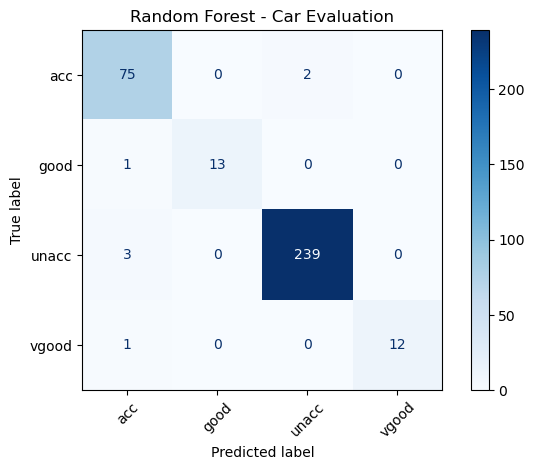


New Car Details:
buying maint doors persons lug_boot safety
   low   low     4    more      big   high

Predicted Car Acceptability: vgood


In [9]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# --------------------------------------------------
# 1. Load the dataset
# --------------------------------------------------

file_path = "car_evaluation.csv"

df = pd.read_csv(file_path)

# Clean column names
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
)

# Expected columns in the Car Evaluation dataset
columns = [
    "buying",
    "maint",
    "doors",
    "persons",
    "lug_boot",
    "safety",
    "class"
]

# Handle CSV files that do not contain a header row
if not set(columns).issubset(df.columns):
    df = pd.read_csv(file_path, header=None)

    # Remove a possible header row if present
    first_row = df.iloc[0].astype(str).str.strip().str.lower().tolist()

    if first_row == columns:
        df = df.iloc[1:].reset_index(drop=True)

    if df.shape[1] == 7:
        df.columns = columns
    elif df.shape[1] == 8:
        # Some versions include an ID column
        df.columns = ["id"] + columns
        df = df.drop(columns=["id"])
    else:
        raise ValueError(
            f"Expected 7 dataset columns, but found {df.shape[1]}. "
            f"Please check your CSV file."
        )

# Remove common unnecessary index columns
df = df.drop(
    columns=["unnamed: 0", "id"],
    errors="ignore"
)

# Verify dataset columns
print("Dataset columns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())

print("\nDataset shape:", df.shape)

# --------------------------------------------------
# 2. Prepare the data
# --------------------------------------------------

features = [
    "buying",
    "maint",
    "doors",
    "persons",
    "lug_boot",
    "safety"
]

target = "class"

if not set(features + [target]).issubset(df.columns):
    raise ValueError(
        "Incorrect dataset columns. "
        "Expected buying, maint, doors, persons, "
        "lug_boot, safety, and class."
    )

# Remove missing values from required columns
df = df.dropna(subset=features + [target]).copy()

# Convert categorical values to clean strings
for col in features + [target]:
    df[col] = df[col].astype(str).str.strip().str.lower()

# Normalize a common variation in the target label
df[target] = df[target].replace({"v-good": "vgood"})

X = df[features]
y = df[target]

print("\nClass distribution:")
print(y.value_counts())

# --------------------------------------------------
# 3. Split the dataset
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# --------------------------------------------------
# 4. Encode categorical features
# --------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            features
        )
    ]
)

# --------------------------------------------------
# 5. Create the Random Forest model
# --------------------------------------------------

model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=100,
                random_state=42,
                class_weight="balanced"
            )
        )
    ]
)

# --------------------------------------------------
# 6. Train the model
# --------------------------------------------------

model.fit(X_train, y_train)

print("\nRandom Forest model trained successfully!")

# --------------------------------------------------
# 7. Make predictions
# --------------------------------------------------

y_pred = model.predict(X_test)

# --------------------------------------------------
# 8. Evaluate the model
# --------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

print("\nModel Evaluation")
print("------------------------------")
print(f"Accuracy: {accuracy * 100:.2f}%")

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred,
        labels=model.classes_
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

# --------------------------------------------------
# 9. Display the confusion matrix
# --------------------------------------------------

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=model.classes_,
    display_labels=model.classes_,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Random Forest - Car Evaluation")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 10. Predict the acceptability of a new car
# --------------------------------------------------

new_car = pd.DataFrame([
    {
        "buying": "low",
        "maint": "low",
        "doors": "4",
        "persons": "more",
        "lug_boot": "big",
        "safety": "high"
    }
])

prediction = model.predict(new_car)[0]

print("\nNew Car Details:")
print(new_car.to_string(index=False))

print("\nPredicted Car Acceptability:", prediction)
